Training Completed!
Q-table:
[[17.84858723 25.4294     17.8556982  17.87410968]
 [21.42580472 29.366      21.42300741 21.83761356]
 [25.36270509 25.39690978 33.74       25.42475542]
 [18.49770254 19.28752377 18.95775057 29.36165373]
 [ 0.          0.          0.          0.        ]
 [ 0.          0.          0.          0.        ]
 [29.36151476 29.73634079 38.6        29.73936739]
 [ 0.          0.          0.          0.        ]
 [ 9.74488481 32.04615788  2.84103425 12.84807722]
 [26.04610584 38.59894397 27.08093497 24.06959708]
 [33.73802671 44.         34.58990061 33.73004096]
 [39.9237757  39.97228314 50.         38.55487697]
 [13.98397919 -2.6093349  -3.29156555 -4.33150742]
 [ 0.          0.          0.          0.        ]
 [ 0.          0.          0.          0.        ]
 [ 0.          0.          0.          0.        ]]


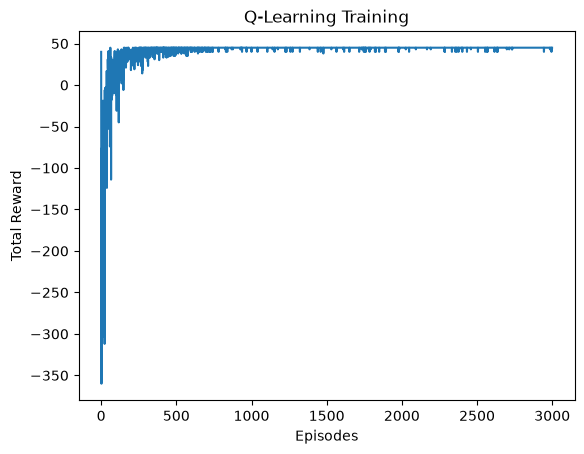

Learned Path: [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (2, 3), (3, 3)]

Maze Path:
S * * .
# # * #
. . * *
. # # G


In [9]:
# Import libraries
import numpy as np
import random
import matplotlib.pyplot as plt

# Create maze (0 = empty, 1 = wall)
maze = np.array([
    [0, 0, 0, 0],
    [1, 1, 0, 1],
    [0, 0, 0, 0],
    [0, 1, 1, 0]
])

start = (0, 0)
goal = (3, 3)

# Actions: Up, Right, Down, Left
actions = [(-1, 0), (0, 1), (1, 0), (0, -1)]

# Create Q-table
# Create a Q-table with 16 possible grid positions and 4 possible actions.
Q = np.zeros((16, 4))

# Parameters
# Learning rate: controls how much a new experience changes the old Q-value.
alpha = 0.1
# Discount factor: controls how much future rewards matter.
gamma = 0.9
# Exploration probability starts at 1, meaning the agent initially chooses random actions.
epsilon = 1.0
rewards = []

# Convert position into state
def get_state(pos):
    # Convert a (row, column) position into one state number from 0 to 15.
    return pos[0] * 4 + pos[1]

# Train the agent
# Train the agent for 3000 attempts, called episodes.
for episode in range(3000):

    position = start
    total_reward = 0

    # Allow at most 100 moves in one episode to prevent endless wandering.
    for step in range(100):

        state = get_state(position)

        # Choose action
        # Choose a random action with probability epsilon; otherwise use what the agent has learned.
        if random.random() < epsilon:
            # Choose one of the four actions randomly.
            action = random.randint(0, 3)
        else:
            # Choose the action with the highest learned Q-value for the current state.
            action = np.argmax(Q[state])

        # Move agent
        # Calculate the next row using the selected action's row movement.
        r = position[0] + actions[action][0]
        # Calculate the next column using the selected action's column movement.
        c = position[1] + actions[action][1]

        # Check wall and boundary
        # Check whether the destination cell is a wall.
        if r < 0 or r >= 4 or c < 0 or c >= 4 or maze[r][c] == 1:
            # For an invalid move, keep the agent in its current position.
            next_position = position
            # Give a strong negative reward for hitting a wall or leaving the maze.
            reward = -5
        else:
            next_position = (r, c)
            # Give a small step penalty to encourage shorter paths.
            reward = -1

        # Check goal
        # Check whether the agent has reached the goal position.
        done = (next_position == goal)

        if done:
            # Give a large positive reward for reaching the goal.
            reward = 50

        # Convert the next position into a state number for the Q-table.
        next_state = get_state(next_position)

        # Update Q-table
        # Update the Q-value for taking this action in the current state.
        Q[state, action] += alpha * (
            # Q-learning error = immediate reward + best discounted future value − current estimate.
            reward + gamma * np.max(Q[next_state]) - Q[state, action]
        )

        # Move the agent to the position reached by this action.
        position = next_position
        total_reward += reward

        if done:
            break

    rewards.append(total_reward)
    # Reduce random exploration gradually, but keep it at or above 0.01 (1%).
    epsilon = max(0.01, epsilon * 0.995)

# Display results
print("Training Completed!")
print("Q-table:")
print(Q)

# Plot training rewards
plt.plot(rewards)
plt.xlabel("Episodes")
plt.ylabel("Total Reward")
plt.title("Q-Learning Training")
plt.show()

# Find learned path
position = start
path = [position]

for step in range(30):

    state = get_state(position)
    # Choose the action with the highest learned Q-value for the current state.
    action = np.argmax(Q[state])

    # Calculate the next row using the selected action's row movement.
    r = position[0] + actions[action][0]
    # Calculate the next column using the selected action's column movement.
    c = position[1] + actions[action][1]

    # Check whether the destination cell is a wall.
    if r < 0 or r >= 4 or c < 0 or c >= 4 or maze[r][c] == 1:
        break

    position = (r, c)
    path.append(position)

    if position == goal:
        break

# Display learned path
print("Learned Path:", path)

# Draw maze
# Convert the numeric maze into text so symbols such as # and * can be placed in it.
result = maze.astype(str)
# Replace open-cell zeros with dots for easier viewing.
result[result == '0'] = '.'
# Replace wall ones with hash symbols.
result[result == '1'] = '#'

# Loop through each (row, column) coordinate in the learned path.
for r, c in path:
    # Mark each cell visited by the learned path with an asterisk.
    result[r, c] = '*'

# Mark the start cell with S.
result[start] = 'S'
# Mark the goal cell with G.
result[goal] = 'G'

print("\nMaze Path:")
for row in result:
    # Join the symbols in one row with spaces so the maze is readable.
    print(" ".join(row))
